# Phase 1: Data Audit & Risk Evaluation

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

In [6]:
df = pd.read_csv("practise2/ai4i2020.csv")

## Initial dataset overview

In [8]:
df.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  str    
 2   Type                     10000 non-null  str    
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9), str(2)
me

In [10]:
df.isnull().sum()

UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64

In [12]:
df.describe().round(2)

,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.00,10000.0,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00
mean,5000.50,300.0,310.01,1538.78,39.99,107.95,0.03,0.00,0.01,0.01,0.01,0.00
std,2886.90,2.0,1.48,179.28,9.97,63.65,0.18,0.07,0.11,0.10,0.10,0.04
min,1.00,295.3,305.70,1168.00,3.80,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,2500.75,298.3,308.80,1423.00,33.20,53.00,0.00,0.00,0.00,0.00,0.00,0.00
50%,5000.50,300.1,310.10,1503.00,40.10,108.00,0.00,0.00,0.00,0.00,0.00,0.00
75%,7500.25,301.5,311.10,1612.00,46.80,162.00,0.00,0.00,0.00,0.00,0.00,0.00
max,10000.00,304.5,313.80,2886.00,76.60,253.00,1.00,1.00,1.00,1.00,1.00,1.00


In [17]:
print((df['Air temperature [K]'] <= 0).sum())
print((df['Process temperature [K]'] <= 0).sum())
print((df['Rotational speed [rpm]'] < 0).sum())
print((df['Torque [Nm]'] < 0).sum())
print((df['Tool wear [min]'] < 0).sum())

0
0
0
0
0


In [20]:
print(df.duplicated().sum())

0


In [23]:
failure_cols = ['TWF', 'HDF', 'PWF', 'OSF', 'RNF']
df['calculated_failure'] = df[failure_cols].max(axis=1)
inconsistent_flags = df[df['Machine failure'] != df['calculated_failure']]
print(f"\nInconsistent Failure Flag Count: {len(inconsistent_flags)}")


Inconsistent Failure Flag Count: 27


In [25]:
inconsistent_flags

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF,calculated_failure
1221,1222,M16081,M,297.0,308.3,1399,46.4,132,0,0,0,0,0,1,1
1302,1303,L48482,L,298.6,309.8,1505,45.7,144,0,0,0,0,0,1,1
1437,1438,H30851,H,298.8,309.9,1439,45.2,40,1,0,0,0,0,0,0
1748,1749,H31162,H,298.4,307.7,1626,31.1,166,0,0,0,0,0,1,1
2072,2073,L49252,L,299.6,309.5,1570,35.5,189,0,0,0,0,0,1,1
2559,2560,L49739,L,299.3,309.0,1447,50.4,140,0,0,0,0,0,1,1
2749,2750,M17609,M,299.7,309.2,1685,28.9,179,1,0,0,0,0,0,0
3065,3066,M17925,M,300.1,309.2,1687,27.7,95,0,0,0,0,0,1,1
3452,3453,H32866,H,301.6,310.5,1602,32.3,2,0,0,0,0,0,1,1
4044,4045,M18904,M,301.9,310.9,1419,47.7,20,1,0,0,0,0,0,0


* This dataset has no missing values
* All numerical values are within realistic physical bounds.
* There are 0 duplicate records.
* Sensor target flags show 27 logical inconsistencies where specific failure modes don't match with the global `Machine failure` column (Random Failures `RNF` occurring without tripping global failure alerts and global failure indication with no specific failure mode assigned).
* Undetected random anomalies or unmapped failure states could lead to false negatives, triggering catastrophic mechanical breakdowns in real-time operation.

# Phase 2: Sensor Behavior Analysis

In [26]:
numeric_sensors = [
    'Air temperature [K]', 
    'Process temperature [K]', 
    'Rotational speed [rpm]', 
    'Torque [Nm]', 
    'Tool wear [min]'
]

In [27]:
sensor_stats = []

for col in numeric_sensors:
    mean_val = df[col].mean()
    std_val = df[col].std()
    q25, q75 = df[col].quantile(0.25), df[col].quantile(0.75)
    iqr_val = q75 - q25
    
    lower_bound = q25 - 1.5 * iqr_val
    upper_bound = q75 + 1.5 * iqr_val
    extreme_count = ((df[col] < lower_bound) | (df[col] > upper_bound)).sum()

    normal_mean = df[df['Machine failure'] == 0][col].mean()
    failed_mean = df[df['Machine failure'] == 1][col].mean()
    
    sensor_stats.append({
        'Sensor': col,
        'Mean': round(mean_val, 2),
        'Std Dev': round(std_val, 2),
        'IQR': round(iqr_val, 2),
        'Extreme Count': extreme_count,
        'Normal Mean': round(normal_mean, 2),
        'Failed Mean': round(failed_mean, 2),
        'Delta (%)': round(((failed_mean - normal_mean) / normal_mean) * 100, 2)
    })

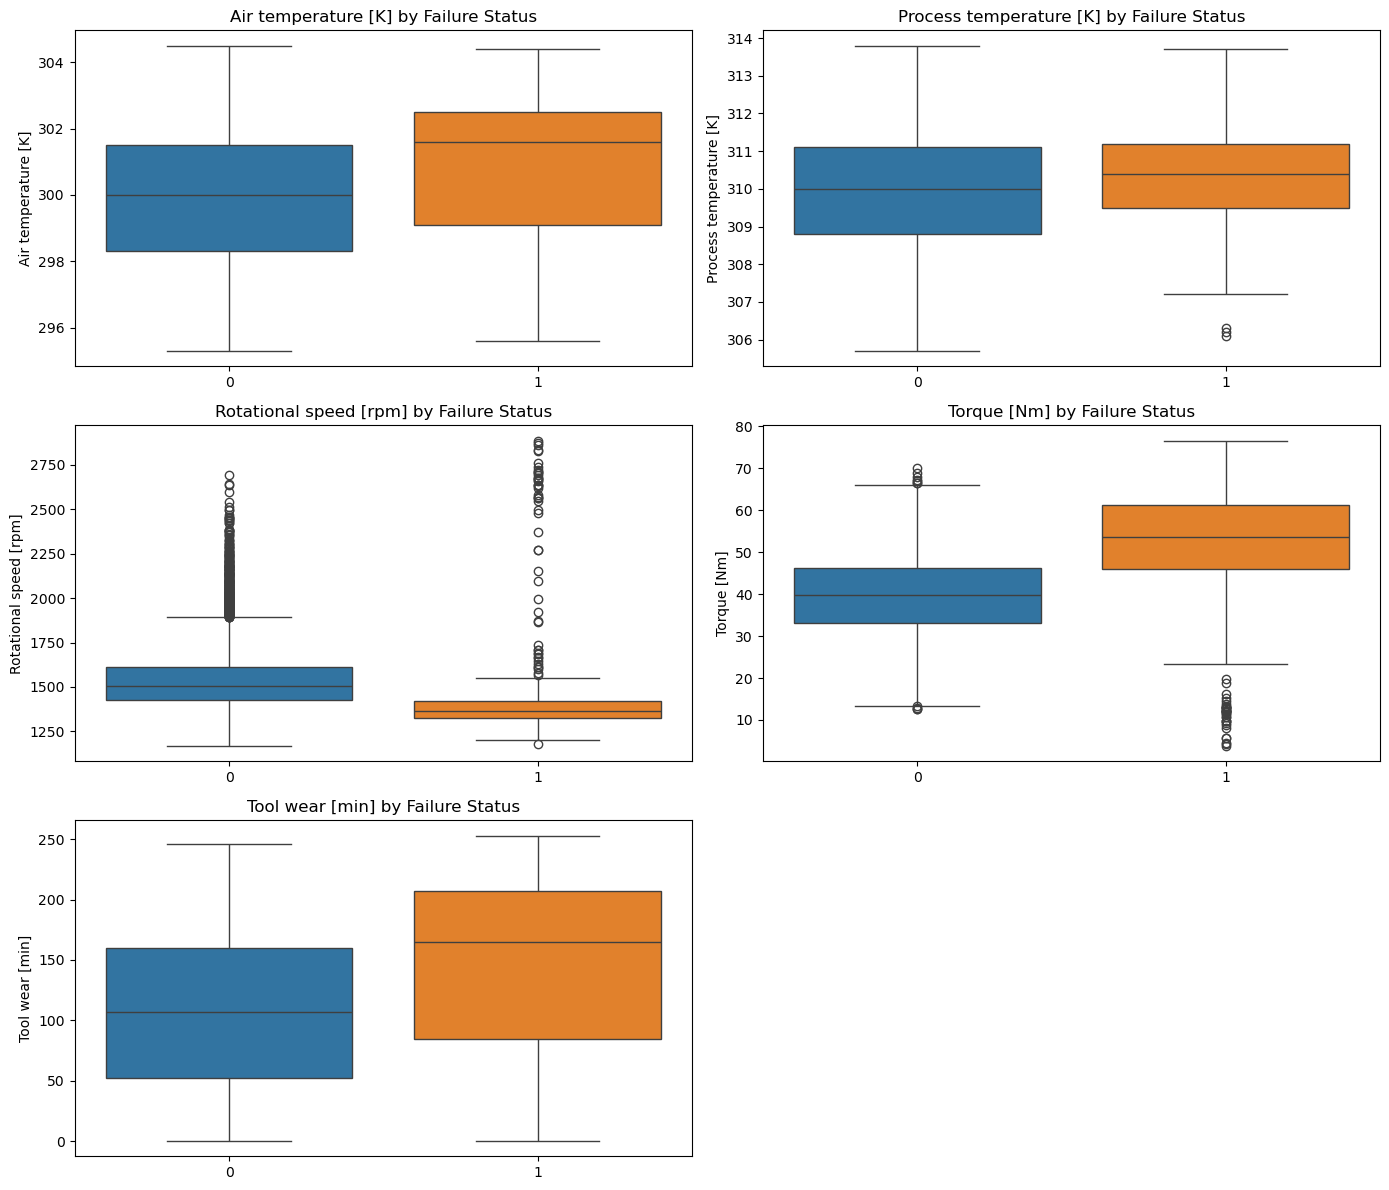

In [39]:
fig, axes = plt.subplots(3, 2, figsize=(14, 12))
axes = axes.flatten()

for i, col in enumerate(numeric_sensors):
    sns.boxplot(data=df, x='Machine failure', y=col, ax=axes[i], hue='Machine failure', legend=False)
    axes[i].set_title(f'{col} by Failure Status')
    axes[i].set_xlabel('')

fig.delaxes(axes[5])

fig.tight_layout()
plt.show()